# Differences in V-gene sequence composition lead to distinct mutational trajectories through sequence space.

In [1]:
import pandas as pd
import numpy as np
from scipy.stats import ks_2samp
import tqdm

from Bio import Align
from Bio.Align import substitution_matrices
blosum62 = substitution_matrices.load("BLOSUM62")

import matplotlib.pyplot as plt
import seaborn as sn
from scripts.functions.colors import shm_colors
color_red = shm_colors['color_red']
color_yellow = shm_colors['color_yellow']
color_blue = shm_colors['color_blue']
color_violet = shm_colors['color_violet']
color_gray = shm_colors['color_gray']

from scripts.functions import mutation_matrix as mm
from scripts.functions import Gillespie_algorithm as ga
from scripts.functions import plotting as plo
from scripts.functions import diversity as div
from scripts.functions import cdr_kmers_generation as cdr

muts = pd.read_csv('data/Spisak_mutabilities_context.tsv', sep ="\t")

### k-mers
l_seq = 9
l_context = 2
sequences = mm.generate_all_sequences(l_seq)
sequence_to_index = {seq: idx for idx, seq in enumerate(sequences)}
mutation_matrix_sp = mm.compute_mutmatrix(sequences, muts, l_seq, l_context)

conn_dict_kmer = mm.connectivity(sequences)
right_eigvals_real, stat_freq_norm, v1, v2 = mm.k_eigenvectors_phased(10, mutation_matrix_sp, sequences)

kmers_df = pd.DataFrame(columns = ['seq_id', 'sequence', 'log stat freq', 'v1.real', 'v2.real', 'v2.imag'])
## rotate v2 so CCCCTGGGG lies on the positive imaginary axis
target_seq = 'CCCCTGGGG'
target_idx = np.where(np.asarray(sequences) == target_seq)[0][0]
z = v2[target_idx]
if np.isclose(np.abs(z), 0):
    raise ValueError(f"{target_seq} is too close to the origin to define a rotation.")
## desired angle = 90 degrees = positive imaginary axis
target_angle = np.pi / 2
## rotation angle
theta = target_angle - np.angle(z)
## rotate the entire complex eigenvector
v2 = v2 * np.exp(1j * theta)

kmers_df['seq_id'] = list(range(len(sequences)))
kmers_df['sequence'] = sequences
kmers_df['log stat freq'] = np.log(stat_freq_norm.real)
kmers_df['v1.real'] = v1.real
kmers_df['v2.real'] = v2.real
kmers_df['v2.imag'] = v2.imag

### cdrs
cdrs_table = pd.read_csv('data/IMGT_CDR_IGHV.tsv', sep="\t")
cdrs_table = cdrs_table[cdrs_table['type'] == 'F']
cdrs_table = cdrs_table[['gene', 'CDR', 'n_length', 'reading_frame', 'aa_length', 'aa_sequence',
                         'nt_sequence']].drop_duplicates().reset_index(drop=True)
cdrs_table["gene_class"] = cdrs_table["gene"].str.strip().str[4]

100%|██████████| 589824/589824 [00:01<00:00, 471697.35it/s]


## a-b: Distribution and simulated mutation trajectories of 9-mers derived from CDR1 (red) and CDR2 (yellow) regions of V genes from the IGHV1 (left) and IGHV3 (right) gene families.

Distribution of initial 9-mers along diffusion axis 1.

100%|██████████| 351/351 [00:00<00:00, 105443.40it/s]


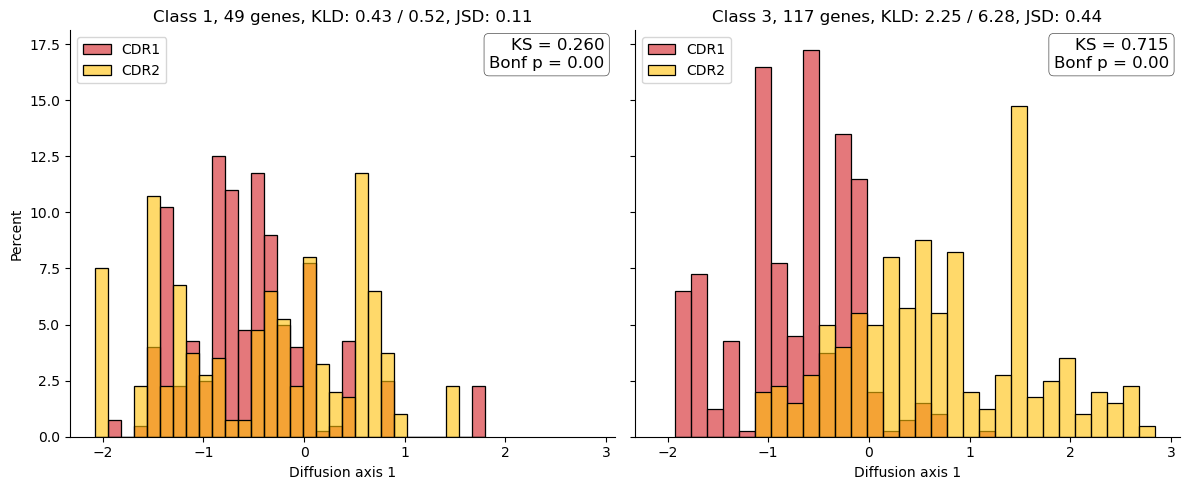

In [2]:
genes = ['1', '3']
nrows, ncols = 1, 2
sampled_kmers = 400
rng = np.random.default_rng(123)

fig, axes = plt.subplots(nrows, ncols, figsize=(12, 5), sharex=True, sharey=True)
axes = axes.ravel()

# fast mapping from sequence -> index
seq_to_idx = {s: i for i, s in enumerate(sequences)}

for x, g in enumerate(genes):
    ngenes, cdr1_class, cdr2_class, cdr1_idx, cdr2_idx = cdr.kmer_gene_generation(cdrs_table, l_seq, 'gene_class', g, seq_to_idx, downsample = False)
    cdr1_idx = rng.choice(cdr1_idx, size=sampled_kmers, replace=False)
    cdr2_idx = rng.choice(cdr2_idx, size=sampled_kmers, replace=False)

    x1 = v1[cdr1_idx].real
    x2 = v1[cdr2_idx].real

    ax = axes[x]
    edges = np.histogram_bin_edges(np.concatenate([x1, x2]), bins=30)

    sn.histplot(x1, bins=edges, fill=True, label='CDR1', ax=ax,
                alpha=0.6, stat='percent', kde=False, color = color_red)
    sn.histplot(x2, bins=edges, fill=True, label='CDR2', ax=ax,
                alpha=0.6, stat='percent', kde=False, color = color_yellow)


    ncdr1k = len(set(cdr1_class))
    ncdr2k = len(set(cdr2_class))
    kl_pq, kl_qp, js = div.compute_divergence(x1, x2, epsilon=1e-12, kde = True)
    ax.set_title(f'Class {g}, {ngenes} genes, KLD: {kl_pq:.2f} / {kl_qp:.2f}, JSD: {js:.2f}')

    ## KS test
    ks_stat, p = ks_2samp(x1, x2)
    p_bonf = min(p * len(genes), 1.0)
    ax.text(
        0.98, 0.98,
        f"KS = {ks_stat:.3f}\nBonf p = {p_bonf:.2f}",
        transform=ax.transAxes,
        ha='right', va='top',
        fontsize=12,
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7, linewidth=0.5)
    )

    ax.set_xlabel('Diffusion axis 1')
    ax.legend()

plt.tight_layout()
sn.despine()

9-mers visited during 100 simulations till $t = 1$, starting from 100 randomly sampled 9-mers derived from CDR1 and CDR2 sequences, respectively. Circle size indicates the number of visits to each 9-mer, with only sequences visited more than 5 times highlighted.

100%|██████████| 100/100 [00:48<00:00,  2.06it/s]


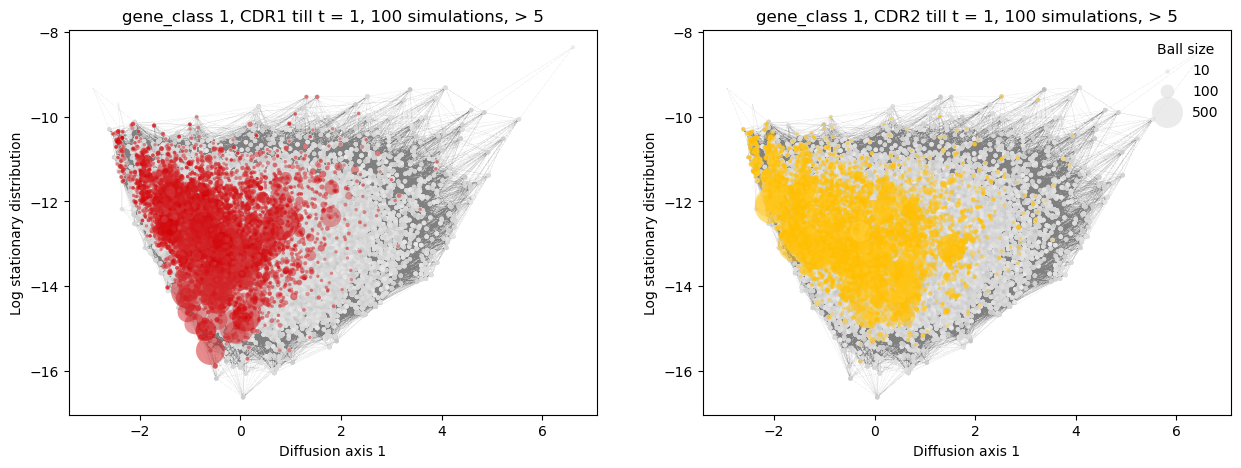

In [3]:
time_stop = 1
n_repeats = 100
gene_class = '1'
downsample = 30
sampled_kmers = 100
more = 5

_, gene3_kcdr1, gene3_kcdr2, gene3_cdr1_idx, gene3_cdr2_idx = cdr.kmer_gene_generation(cdrs_table, l_seq, 'gene_class', gene_class, seq_to_idx, downsample = False, unique = False)

gene3_kcdr1 = np.random.choice(gene3_kcdr1, size = sampled_kmers, replace = False)
gene3_kcdr2 = np.random.choice(gene3_kcdr2, size = sampled_kmers, replace = False)

count_map3_1 = ga.traj_counts(gene3_kcdr1, n_repeats, mutation_matrix_sp, time_stop = time_stop)
count_map3_2 = ga.traj_counts(gene3_kcdr2, n_repeats, mutation_matrix_sp, time_stop = time_stop)

count_maps_all1 = [count_map3_1]
start_seqs_all1 = [gene3_kcdr1]
count_maps_all2 = [count_map3_2]
start_seqs_all2 = [gene3_kcdr2]

## collecting table
count1 = pd.DataFrame(count_map3_1, index = [0]).T.reset_index()
count1.columns = ['sequence', 'visited']
count2 = pd.DataFrame(count_map3_2, index = [0]).T.reset_index()
count2.columns = ['sequence', 'visited']

count1 = count1.merge(kmers_df, on = 'sequence', how = 'right')
count2 = count2.merge(kmers_df, on = 'sequence', how = 'right')

all_dots = plo.normal_palette(color_gray,  n=len(kmers_df), sigma_h=0, sigma_s=0, sigma_v=0.05, seed=123)
count1['color'] = all_dots
count2['color'] = all_dots

visited_colors1 = plo.normal_palette(color_red,  n=len(count1[count1['visited'] > 0]), sigma_h=0, sigma_s=0.1, sigma_v=0, seed=123)
count1.loc[count1['visited'] > 0, 'color'] = visited_colors1

visited_colors2 = plo.normal_palette(color_yellow,  n=len(count2[count2['visited'] > 0]), sigma_h=0, sigma_s=0.1, sigma_v=0, seed=123)
count2.loc[count2['visited'] > 0, 'color'] = visited_colors2

count1.loc[count1['visited'].isnull(), 'visited'] = 0
count2.loc[count2['visited'].isnull(), 'visited'] = 0
count1['visited'] = count1['visited'] * 2
count2['visited'] = count2['visited'] * 2

## plots

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

vis_x = 'v1.real'
vis_y = 'log stat freq'

## all edges
plo.add_edges(conn_dict_kmer, kmers_df[vis_x].to_numpy(), kmers_df[vis_y].to_numpy(),
              ax=axes[0], color='gray', linewidth=0.03, alpha=0.1)
plo.add_edges(conn_dict_kmer, kmers_df[vis_x].to_numpy(), kmers_df[vis_y].to_numpy(),
              ax=axes[1], color='gray', linewidth=0.03, alpha=0.1)

### CDR1
ax = axes[0]
ax.scatter(data = count1[count1['visited'] == 0], x = vis_x, y = vis_y , s=10, c = 'color',
                alpha=0.5, edgecolor='white', linewidth=0.01, zorder=1, rasterized=True)
ax.scatter(data = count1[count1['visited'] > more], x = vis_x, y = vis_y , s='visited', c = 'color',
                alpha=0.5, edgecolor='white', linewidth=0.01, zorder=1, rasterized=True)
ax.set_title(f'gene_class {gene_class}, CDR1 till t = {time_stop}, {n_repeats} simulations, > {more}')

### CDR2
ax = axes[1]
ax.scatter(data = count2[count2['visited'] == 0], x = vis_x, y = vis_y , s=10, c = 'color',
                alpha=0.5, edgecolor='white', linewidth=0.01, zorder=1, rasterized=True)
ax.scatter(data = count2[count2['visited'] > more], x = vis_x, y = vis_y , s='visited', c = 'color',
                alpha=0.5, edgecolor='white', linewidth=0.01, zorder=1, rasterized=True)

ax.set_title(f'gene_class {gene_class}, CDR2 till t = {time_stop}, {n_repeats} simulations, > {more}')

for ax in axes:
    ax.set_xlabel('Diffusion axis 1')
    ax.set_ylabel('Log stationary distribution')

## ball sizes
legend_sizes = set([10, 100, 500])
legend_handles = [plt.scatter([], [], s=size, c=color_gray, alpha=0.5, edgecolor='white', linewidth=0.01) for size in legend_sizes]
axes[1].legend(legend_handles, [str(size) for size in legend_sizes], title='Ball size', loc='upper right', frameon=False)

100%|██████████| 100/100 [00:49<00:00,  2.02it/s]


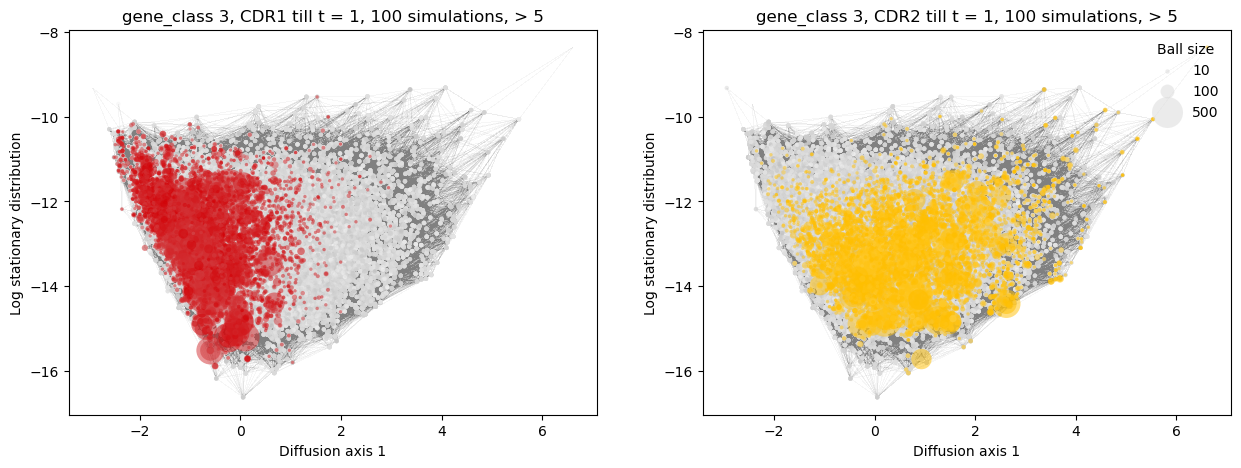

In [4]:
time_stop = 1
n_repeats = 100
gene_class = '3'
downsample = 30
sampled_kmers = 100
more = 5

_, gene3_kcdr1, gene3_kcdr2, gene3_cdr1_idx, gene3_cdr2_idx = cdr.kmer_gene_generation(cdrs_table, l_seq, 'gene_class', gene_class, seq_to_idx, downsample = False, unique = False)

gene3_kcdr1 = np.random.choice(gene3_kcdr1, size = sampled_kmers, replace = False)
gene3_kcdr2 = np.random.choice(gene3_kcdr2, size = sampled_kmers, replace = False)

count_map3_1 = ga.traj_counts(gene3_kcdr1, n_repeats, mutation_matrix_sp, time_stop = time_stop)
count_map3_2 = ga.traj_counts(gene3_kcdr2, n_repeats, mutation_matrix_sp, time_stop = time_stop)

count_maps_all1 = [count_map3_1]
start_seqs_all1 = [gene3_kcdr1]
count_maps_all2 = [count_map3_2]
start_seqs_all2 = [gene3_kcdr2]

## collecting table
count1 = pd.DataFrame(count_map3_1, index = [0]).T.reset_index()
count1.columns = ['sequence', 'visited']
count2 = pd.DataFrame(count_map3_2, index = [0]).T.reset_index()
count2.columns = ['sequence', 'visited']

count1 = count1.merge(kmers_df, on = 'sequence', how = 'right')
count2 = count2.merge(kmers_df, on = 'sequence', how = 'right')

all_dots = plo.normal_palette(color_gray,  n=len(kmers_df), sigma_h=0, sigma_s=0, sigma_v=0.05, seed=123)
count1['color'] = all_dots
count2['color'] = all_dots

visited_colors1 = plo.normal_palette(color_red,  n=len(count1[count1['visited'] > 0]), sigma_h=0, sigma_s=0.1, sigma_v=0, seed=123)
count1.loc[count1['visited'] > 0, 'color'] = visited_colors1

visited_colors2 = plo.normal_palette(color_yellow,  n=len(count2[count2['visited'] > 0]), sigma_h=0, sigma_s=0.1, sigma_v=0, seed=123)
count2.loc[count2['visited'] > 0, 'color'] = visited_colors2

count1.loc[count1['visited'].isnull(), 'visited'] = 0
count2.loc[count2['visited'].isnull(), 'visited'] = 0
count1['visited'] = count1['visited'] * 2
count2['visited'] = count2['visited'] * 2

## plots

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

vis_x = 'v1.real'
vis_y = 'log stat freq'

## all edges
plo.add_edges(conn_dict_kmer, kmers_df[vis_x].to_numpy(), kmers_df[vis_y].to_numpy(),
              ax=axes[0], color='gray', linewidth=0.03, alpha=0.1)
plo.add_edges(conn_dict_kmer, kmers_df[vis_x].to_numpy(), kmers_df[vis_y].to_numpy(),
              ax=axes[1], color='gray', linewidth=0.03, alpha=0.1)

### CDR1
ax = axes[0]
ax.scatter(data = count1[count1['visited'] == 0], x = vis_x, y = vis_y , s=10, c = 'color',
                alpha=0.5, edgecolor='white', linewidth=0.01, zorder=1, rasterized=True)
ax.scatter(data = count1[count1['visited'] > more], x = vis_x, y = vis_y , s='visited', c = 'color',
                alpha=0.5, edgecolor='white', linewidth=0.01, zorder=1, rasterized=True)
ax.set_title(f'gene_class {gene_class}, CDR1 till t = {time_stop}, {n_repeats} simulations, > {more}')

### CDR2
ax = axes[1]
ax.scatter(data = count2[count2['visited'] == 0], x = vis_x, y = vis_y , s=10, c = 'color',
                alpha=0.5, edgecolor='white', linewidth=0.01, zorder=1, rasterized=True)
ax.scatter(data = count2[count2['visited'] > more], x = vis_x, y = vis_y , s='visited', c = 'color',
                alpha=0.5, edgecolor='white', linewidth=0.01, zorder=1, rasterized=True)

ax.set_title(f'gene_class {gene_class}, CDR2 till t = {time_stop}, {n_repeats} simulations, > {more}')

for ax in axes:
    ax.set_xlabel('Diffusion axis 1')
    ax.set_ylabel('Log stationary distribution')

## ball sizes
legend_sizes = set([10, 100, 500])
legend_handles = [plt.scatter([], [], s=size, c=color_gray, alpha=0.5, edgecolor='white', linewidth=0.01) for size in legend_sizes]
axes[1].legend(legend_handles, [str(size) for size in legend_sizes], title='Ball size', loc='upper right', frameon=False)